# Eixo 3 — Realidade

## Pergunta de investigação

Como os participantes caracterizam sua realidade profissional e que percepções expressam sobre a experiência de trabalhar na área de tecnologia?

## Objetivo

Compreender como os participantes percebem e caracterizam seu cotidiano profissional, avaliando a correspondência entre a realidade vivenciada e suas expectativas iniciais, além de identificar o que consideram importante para quem está começando na área.

## Variáveis analisadas

- Características do cotidiano profissional;
- Correspondência entre realidade e expectativas;
- Recomendações para quem está começando na área.

## Estratégia de análise

A investigação será organizada em três dimensões:

1. **Cotidiano profissional:** identificar as características mais presentes nas respostas dos participantes sobre sua rotina de trabalho.
2. **Realidade e expectativa:** analisar como os participantes avaliam a correspondência entre a realidade profissional e aquilo que imaginavam quando começaram.
3. **Recomendações para iniciantes:** identificar os conhecimentos, as competências e as experiências consideradas importantes para quem está começando na área.

A análise também poderá incluir cruzamentos exploratórios, desde que contribuam para aprofundar a compreensão dos resultados e respeitem a estrutura das variáveis.

## Cuidados metodológicos

As perguntas sobre cotidiano profissional e recomendações permitem múltiplas seleções. Portanto, as frequências representam marcações, e não categorias exclusivas de participantes. A soma dos percentuais poderá ultrapassar 100%.

A pergunta sobre correspondência entre realidade e expectativa utiliza uma escala de 1 a 5. Sua interpretação deverá considerar os rótulos e o significado original de cada valor no questionário.

Os resultados caracterizam exclusivamente as percepções dos 54 participantes da amostra investigada, sem pretensão de representatividade estatística do conjunto dos profissionais de tecnologia.

# 01 — Preparação e verificação da base

*Importações, carregamento da fonte original, verificação de integridade e seleção das variáveis.*

In [20]:
# 01 — Preparação da base

# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Configurações de exibição
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Diretório de execução
diretorio_atual = Path.cwd()

print("Ambiente de análise preparado.")

Ambiente de análise preparado.


In [21]:
# Carregamento da base original

# NOTA SOBRE A VERSÃO DA BASE:
# O arquivo mantém o nome BASELINE_36_RESPOSTAS.csv,
# referente à versão inicial da coleta.
# Seu conteúdo foi atualizado posteriormente e
# corresponde à base consolidada com 54 respostas.

caminho_fonte = (
    diretorio_atual
    / ".."
    / ".."
    / "data"
    / "fonte_original"
    / "Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv"
).resolve()

if not caminho_fonte.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_fonte}")

df_original = pd.read_csv(caminho_fonte)

print(f"Arquivo: {caminho_fonte.name}")
print(
    f"Dimensões da base: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas"
)

Arquivo: Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv
Dimensões da base: 54 linhas × 17 colunas


In [22]:
# 01 — Preparação e verificação da base

# 1. Identificação das colunas
colunas_disponiveis = {coluna.strip(): coluna for coluna in df_original.columns}

coluna_cotidiano = colunas_disponiveis[
    "O que mais define seu cotidiano profissional hoje?"
]

coluna_expectativa = colunas_disponiveis[
    "Quanto sua realidade profissional corresponde ao que você imaginava quando começou?"
]

coluna_recomendacoes = colunas_disponiveis[
    "O que você considera mais importante para quem está começando na sua área?"
]

colunas_realidade = [coluna_cotidiano, coluna_expectativa, coluna_recomendacoes]

# 2. Seleção das variáveis
df_realidade = df_original[colunas_realidade].copy()

# 3. Verificação das dimensões
print("DIMENSÕES DA BASE")

print(
    f"Base original: {df_original.shape[0]} linhas " f"e {df_original.shape[1]} colunas"
)

print(
    f"Base do Eixo 3: {df_realidade.shape[0]} linhas "
    f"e {df_realidade.shape[1]} colunas"
)

# 4. Verificação de valores ausentes
print("\nVALORES AUSENTES — BASE DO EIXO 3")

display(df_realidade.isna().sum().to_frame("respostas_ausentes"))

# 5. Verificação de duplicidade
print("\nVERIFICAÇÃO DE DUPLICIDADE")

print(
    "Linhas integralmente idênticas na base original:", df_original.duplicated().sum()
)

print("Linhas idênticas nas três variáveis do Eixo 3:", df_realidade.duplicated().sum())

# 6. Quantidade de seleções — cotidiano profissional
print("\nQUANTIDADE DE CARACTERÍSTICAS SELECIONADAS POR PARTICIPANTE")

quantidade_cotidiano = (
    df_realidade[coluna_cotidiano]
    .dropna()
    .apply(lambda resposta: len([item for item in resposta.split(",") if item.strip()]))
    .value_counts()
    .sort_index()
)

display(quantidade_cotidiano.to_frame("participantes"))

# 7. Distribuição das respostas — realidade e expectativa
print("\nDISTRIBUIÇÃO DA ESCALA — REALIDADE E EXPECTATIVA")

distribuicao_expectativa = (
    df_realidade[coluna_expectativa].value_counts(dropna=False).sort_index()
)

display(distribuicao_expectativa.to_frame("participantes"))

# 8. Quantidade de seleções — recomendações
print("\nQUANTIDADE DE RECOMENDAÇÕES SELECIONADAS POR PARTICIPANTE")

quantidade_recomendacoes = (
    df_realidade[coluna_recomendacoes]
    .dropna()
    .apply(lambda resposta: len([item for item in resposta.split(",") if item.strip()]))
    .value_counts()
    .sort_index()
)

display(quantidade_recomendacoes.to_frame("participantes"))

# 9. Conferência das variáveis selecionadas
print("\nVARIÁVEIS ANALISADAS")

for coluna in colunas_realidade:
    print(f"- {coluna}")

print("\nVERIFICAÇÃO CONCLUÍDA.")

DIMENSÕES DA BASE
Base original: 54 linhas e 17 colunas
Base do Eixo 3: 54 linhas e 3 colunas

VALORES AUSENTES — BASE DO EIXO 3


,respostas_ausentes
O que mais define seu cotidiano profissional hoje?,0
Quanto sua realidade profissional corresponde ao que você imaginava quando começou?,0
O que você considera mais importante para quem está começando na sua área?,0



VERIFICAÇÃO DE DUPLICIDADE
Linhas integralmente idênticas na base original: 0
Linhas idênticas nas três variáveis do Eixo 3: 0

QUANTIDADE DE CARACTERÍSTICAS SELECIONADAS POR PARTICIPANTE


,participantes
O que mais define seu cotidiano profissional hoje?,
1,3
2,5
3,8
4,38



DISTRIBUIÇÃO DA ESCALA — REALIDADE E EXPECTATIVA


,participantes
Quanto sua realidade profissional corresponde ao que você imaginava quando começou?,
1,1
2,3
3,22
4,17
5,11



QUANTIDADE DE RECOMENDAÇÕES SELECIONADAS POR PARTICIPANTE


,participantes
O que você considera mais importante para quem está começando na sua área?,
1,2
2,6
3,38
4,3
5,3
6,2



VARIÁVEIS ANALISADAS
- O que mais define seu cotidiano profissional hoje? 
- Quanto sua realidade profissional corresponde ao que você imaginava quando começou? 
- O que você considera mais importante para quem está começando na sua área? 

VERIFICAÇÃO CONCLUÍDA.


## 02 — Cotidiano profissional

Identificação das características mais presentes na rotina de trabalho dos participantes, considerando as opções assinaladas no questionário.

A análise considera a frequência de participantes que selecionaram cada característica. Como a questão permite múltiplas escolhas, os percentuais não representam categorias exclusivas e podem ultrapassar 100% quando somados.

,Participantes,Percentual (%)
O que mais define seu cotidiano profissional hoje?,,
Resolução de problemas,39,72.2
Aprendizado contínuo,37,68.5
Conhecimento técnico,26,48.1
Comunicação e colaboração,24,44.4
Adaptação a mudanças,19,35.2
Gestão de prioridades,18,33.3
Criatividade,10,18.5
Autonomia,10,18.5
Prazos e pressão por entregas,6,11.1


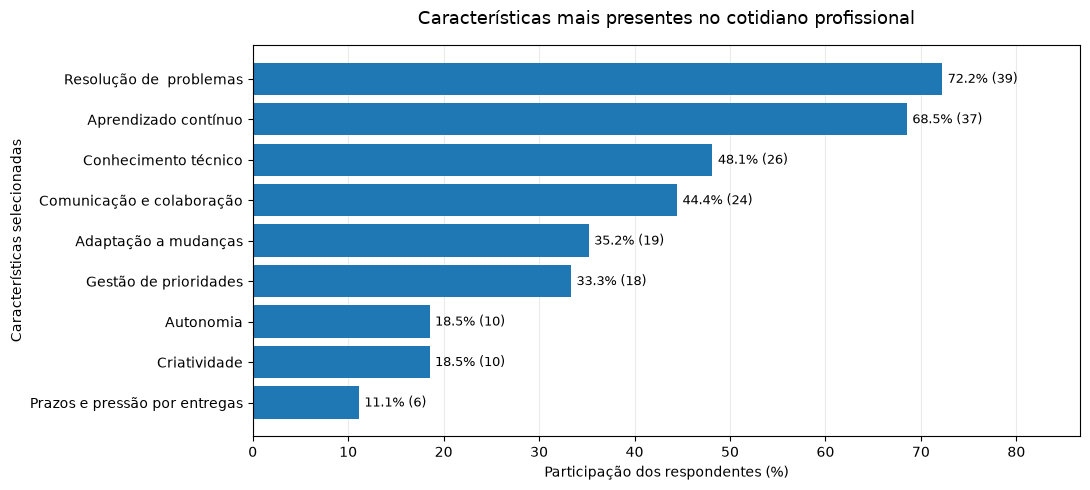

In [23]:
# 02 — Distribuição das características do cotidiano profissional

# 1. Separação das respostas múltiplas
respostas_cotidiano = (
    df_realidade[coluna_cotidiano].dropna().str.split(",").explode().str.strip()
)

# 2. Frequência de cada característica
frequencia_cotidiano = respostas_cotidiano.value_counts().sort_values(ascending=True)

# 3. Percentual em relação ao total de participantes válidos
total_participantes = df_realidade[coluna_cotidiano].notna().sum()

percentual_cotidiano = frequencia_cotidiano / total_participantes * 100

# 4. Tabela de resultados
tabela_cotidiano = pd.DataFrame(
    {
        "Participantes": frequencia_cotidiano,
        "Percentual (%)": percentual_cotidiano.round(1),
    }
)

display(tabela_cotidiano.sort_values("Participantes", ascending=False))

# 5. Visualização
fig, ax = plt.subplots(figsize=(11, max(5, len(frequencia_cotidiano) * 0.55)))

barras = ax.barh(frequencia_cotidiano.index, percentual_cotidiano)

ax.bar_label(
    barras,
    labels=[
        f"{percentual:.1f}% ({quantidade})"
        for percentual, quantidade in zip(percentual_cotidiano, frequencia_cotidiano)
    ],
    padding=4,
    fontsize=9,
)

ax.set_title(
    "Características mais presentes no cotidiano profissional", fontsize=13, pad=15
)

ax.set_xlabel("Participação dos respondentes (%)")
ax.set_ylabel("Características selecionadas")
ax.set_xlim(0, percentual_cotidiano.max() * 1.20)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

A resolução de problemas aparece como a característica mais presente no cotidiano profissional, assinalada por 39 participantes (72,2%). Em seguida, destaca-se o aprendizado contínuo, mencionado por 37 participantes (68,5%). O conhecimento técnico ocupa a terceira posição, com 26 participantes (48,1%).

Comunicação e colaboração também apresentam participação expressiva, reunindo 24 indicações (44,4%). Na sequência, aparecem adaptação a mudanças (35,2%) e gestão de prioridades (33,3%).

Autonomia e criatividade foram assinaladas por 10 participantes cada (18,5%), enquanto prazos e pressão por entregas registraram a menor frequência, com 6 indicações (11,1%).

Em conjunto, os resultados apontam para um cotidiano profissional marcado principalmente pela capacidade de solucionar problemas e pela necessidade de atualização contínua, acompanhadas de conhecimentos técnicos e competências de interação e adaptação.

**Implicação metodológica:** os percentuais representam a proporção de participantes que selecionaram cada característica. Como a questão permitia múltiplas escolhas, as categorias não são excludentes e os resultados não devem ser interpretados como uma hierarquia de competências ou como avaliação do nível de domínio dos participantes.

### 2.2 — Combinações das características do cotidiano

Esta etapa investiga como as características selecionadas pelos participantes aparecem combinadas em suas respostas.

A análise considera o conjunto de opções assinaladas por cada participante, identificando as combinações mais recorrentes e sua distribuição na amostra.

O objetivo é observar se determinadas características tendem a aparecer juntas na descrição do cotidiano profissional.

In [24]:
# 2.2 — Combinações das características do cotidiano

# 1. Separação e organização das respostas
combinacoes_cotidiano = (
    df_realidade[coluna_cotidiano]
    .dropna()
    .apply(
        lambda resposta: tuple(
            sorted(item.strip() for item in resposta.split(",") if item.strip())
        )
    )
)

# 2. Contagem das combinações
frequencia_combinacoes = (
    combinacoes_cotidiano.value_counts()
    .rename_axis("Combinação")
    .reset_index(name="Participantes")
)

# 3. Cálculo dos percentuais
total_respostas_validas = len(combinacoes_cotidiano)

frequencia_combinacoes["Percentual (%)"] = (
    frequencia_combinacoes["Participantes"] / total_respostas_validas * 100
).round(1)

# 4. Organização da tabela
frequencia_combinacoes["Combinação"] = frequencia_combinacoes["Combinação"].apply(
    lambda itens: " + ".join(itens)
)

# 5. Exibição dos resultados
print("COMBINAÇÕES DAS CARACTERÍSTICAS DO COTIDIANO")
print(f"Total de participantes: {total_respostas_validas}")
print("Combinações distintas identificadas:", len(frequencia_combinacoes))

display(frequencia_combinacoes)

COMBINAÇÕES DAS CARACTERÍSTICAS DO COTIDIANO
Total de participantes: 54
Combinações distintas identificadas: 39


,Combinação,Participantes,Percentual (%)
0,Aprendizado contínuo + Comunicação e colaboraç...,5,9.3
1,Aprendizado contínuo + Conhecimento técnico + ...,3,5.6
2,Aprendizado contínuo + Comunicação e colaboraç...,3,5.6
3,Aprendizado contínuo + Conhecimento técnico + ...,3,5.6
4,Adaptação a mudanças + Aprendizado contínuo + ...,3,5.6
5,Aprendizado contínuo + Comunicação e colaboraç...,2,3.7
6,Adaptação a mudanças + Comunicação e colaboraç...,2,3.7
7,Resolução de problemas,2,3.7
8,Autonomia + Conhecimento técnico + Prazos e pr...,1,1.9
9,Aprendizado contínuo + Autonomia + Resolução d...,1,1.9


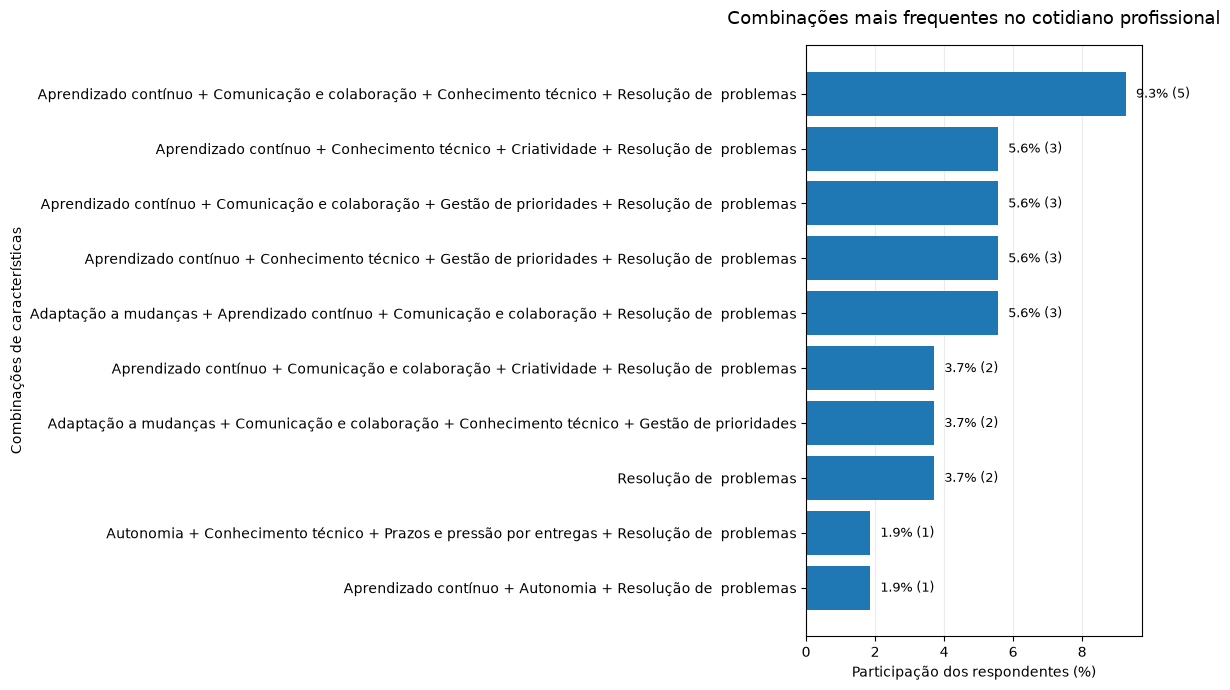

In [25]:
# 2.2 — Visualização das combinações mais frequentes

import matplotlib.pyplot as plt

# 1. Selecionar as 10 combinações mais frequentes
top_combinacoes = frequencia_combinacoes.sort_values(
    by="Participantes", ascending=False
).head(10)

# 2. Calcular os percentuais
percentuais_combinacoes = (
    top_combinacoes["Participantes"] / total_respostas_validas * 100
)

# 3. Preparar os rótulos
rotulos = top_combinacoes["Combinação"].astype(str)

# 4. Construir o gráfico
fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(rotulos, percentuais_combinacoes)

ax.invert_yaxis()

ax.set_title(
    "Combinações mais frequentes no cotidiano profissional", fontsize=13, pad=15
)

ax.set_xlabel("Participação dos respondentes (%)")
ax.set_ylabel("Combinações de características")

# 5. Exibir percentual e quantidade de participantes
for barra, percentual, quantidade in zip(
    barras, percentuais_combinacoes, top_combinacoes["Participantes"]
):
    ax.text(
        barra.get_width() + 0.3,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.1f}% ({quantidade})",
        va="center",
        fontsize=9,
    )

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

A análise identificou **39 combinações distintas** entre as características selecionadas pelos 54 participantes, evidenciando diferentes formas de composição do cotidiano profissional.

A combinação mais frequente reúne aprendizado contínuo, comunicação e colaboração, conhecimento técnico e resolução de problemas, assinalada por 5 participantes (9,3%). Outras combinações aparecem com 3 participantes (5,6%) ou menos, demonstrando que nenhuma configuração concentra parcela expressiva da amostra.

Chama a atenção a presença recorrente de **resolução de problemas e aprendizado contínuo** nas combinações mais frequentes. Esses elementos também se destacaram na análise individual das características, reforçando sua relevância na percepção dos participantes sobre o cotidiano de trabalho.

Em conjunto, os resultados indicam que o cotidiano profissional não é descrito por um conjunto único de competências ou exigências. Ele se configura pela articulação de diferentes características, que variam entre os participantes.

**Implicação metodológica:** as 39 combinações representam agrupamentos das respostas individuais. O gráfico apresenta apenas as dez combinações mais frequentes, enquanto a tabela mantém o registro completo. A baixa concentração nas combinações mais recorrentes recomenda cautela na identificação de padrões predominantes.

## 03 — Realidade e expectativa

Análise da percepção dos participantes sobre a correspondência entre sua realidade profissional atual e as expectativas que tinham quando iniciaram sua trajetória.

A questão utiliza uma escala de 1 a 5. A distribuição das respostas será examinada para identificar concentrações, tendências e possíveis diferenças nas percepções dos participantes.

### Cuidados de interpretação

A escala representa uma avaliação subjetiva dos participantes. A leitura dos resultados deve respeitar os rótulos e o significado atribuídos a cada valor no questionário, sem presumir que a escala represente uma medida objetiva de satisfação ou sucesso profissional.

,Participantes,Percentual (%)
Quanto sua realidade profissional corresponde ao que você imaginava quando começou?,,
1,1,1.9
2,3,5.6
3,22,40.7
4,17,31.5
5,11,20.4



ESTATÍSTICAS DESCRITIVAS
Média: 3.63
Mediana: 4.0
Moda: 3


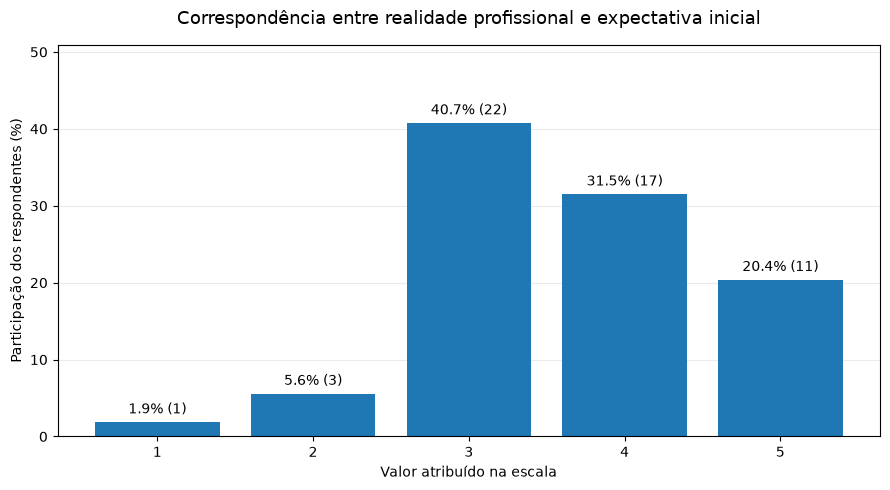

In [26]:
# 03 — Distribuição das respostas: realidade e expectativa

# 1. Frequência das respostas
frequencia_expectativa = df_realidade[coluna_expectativa].value_counts().sort_index()

# 2. Percentual em relação ao total de participantes
total_respostas = df_realidade[coluna_expectativa].notna().sum()

percentual_expectativa = frequencia_expectativa / total_respostas * 100

# 3. Tabela de resultados
tabela_expectativa = pd.DataFrame(
    {
        "Participantes": frequencia_expectativa,
        "Percentual (%)": percentual_expectativa.round(1),
    }
)

display(tabela_expectativa)

# 4. Estatísticas descritivas
print("\nESTATÍSTICAS DESCRITIVAS")

print(f"Média: {df_realidade[coluna_expectativa].mean():.2f}")

print(f"Mediana: {df_realidade[coluna_expectativa].median():.1f}")

print(f"Moda: {df_realidade[coluna_expectativa].mode().iloc[0]}")

# 5. Visualização
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(frequencia_expectativa.index.astype(str), percentual_expectativa)

ax.bar_label(
    barras,
    labels=[
        f"{percentual:.1f}% ({quantidade})"
        for percentual, quantidade in zip(
            percentual_expectativa, frequencia_expectativa
        )
    ],
    padding=4,
    fontsize=10,
)

ax.set_title(
    "Correspondência entre realidade profissional e expectativa inicial",
    fontsize=13,
    pad=15,
)

ax.set_xlabel("Valor atribuído na escala")
ax.set_ylabel("Participação dos respondentes (%)")

ax.set_ylim(0, percentual_expectativa.max() * 1.25)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

As respostas distribuem-se pela escala de 1 a 5, com concentração na parte central e superior. A nota 3 foi a mais frequente, atribuída por 22 participantes (40,7%), seguida pela nota 4, com 17 participantes (31,5%), e pela nota 5, com 11 participantes (20,4%). As notas 1 e 2 foram assinaladas por 4 participantes (7,4%).

Considerando conjuntamente as notas 4 e 5, 28 participantes (51,9%) atribuíram os valores mais altos da escala. A média foi de 3,63, a mediana de 4 e a moda de 3, o que reforça a concentração das respostas entre o ponto intermediário e a parte superior da escala.

A frequência da nota 3 merece atenção: ela foi a mais frequente (40,7%), e a distribuição mostra que as percepções não se concentram em um único valor, com uma parcela expressiva dos participantes no ponto intermediário da escala.

O significado de cada valor deve ser lido conforme os rótulos originais da escala no formulário.

**Implicação metodológica:** a escala registra a percepção declarada pelos participantes sobre a correspondência entre expectativa e realidade profissional. Os resultados não explicam os fatores que produziram essa correspondência ou divergência, nem permitem concluir, isoladamente, sobre satisfação ou insatisfação profissional. A média e a mediana complementam a leitura da distribuição, mas devem ser interpretadas considerando a natureza ordinal da escala.

# 04 — Recomendações para iniciantes

*Conhecimentos, atitudes e orientações que os participantes consideram importantes para quem está começando na área.*

A análise busca identificar quais recomendações são mais mencionadas, como elas se distribuem entre os participantes e quais combinações aparecem nas respostas.

Como a pergunta permite múltiplas seleções, as frequências representam o número de participantes que assinalaram cada recomendação. A soma dos percentuais poderá ultrapassar 100%.

**Nota:** esta pergunta também é retomada no Eixo 4, onde as recomendações selecionadas são lidas junto com as respostas abertas sobre alertas, tendências e recomendações.

In [27]:
# 04.1 — Frequência das recomendações

# 1. Separação das recomendações selecionadas
recomendacoes = (
    df_realidade[coluna_recomendacoes]
    .dropna()
    .apply(
        lambda resposta: list(
            dict.fromkeys(item.strip() for item in resposta.split(",") if item.strip())
        )
    )
)

# 2. Contagem de participantes por recomendação
frequencia_recomendacoes = recomendacoes.explode().value_counts()

# 3. Cálculo dos percentuais sobre o total de participantes
total_participantes = len(df_realidade)

tabela_recomendacoes = pd.DataFrame(
    {
        "Participantes": frequencia_recomendacoes,
        "Percentual (%)": (frequencia_recomendacoes / total_participantes * 100).round(
            1
        ),
    }
)

# 4. Exibição dos resultados
print("RECOMENDAÇÕES PARA QUEM ESTÁ COMEÇANDO")
print(f"Total de participantes: {total_participantes}")
print(f"Total de marcações: {frequencia_recomendacoes.sum()}")
print(f"Categorias identificadas: {len(tabela_recomendacoes)}")

display(tabela_recomendacoes)

RECOMENDAÇÕES PARA QUEM ESTÁ COMEÇANDO
Total de participantes: 54
Total de marcações: 167
Categorias identificadas: 9


,Participantes,Percentual (%)
O que você considera mais importante para quem está começando na sua área?,,
Aprender continuamente,38,70.4
Buscar experiência prática,30,55.6
Desenvolver conhecimento técnico,27,50.0
Desenvolver habilidades comportamentais,25,46.3
Construir uma rede de contatos,18,33.3
Acompanhar tendências do mercado,16,29.6
Conhecer diferentes áreas da tecnologia,11,20.4
visão para a resolução de problemas,1,1.9
Visão de produto e conceitos sólidos de arquitetura,1,1.9


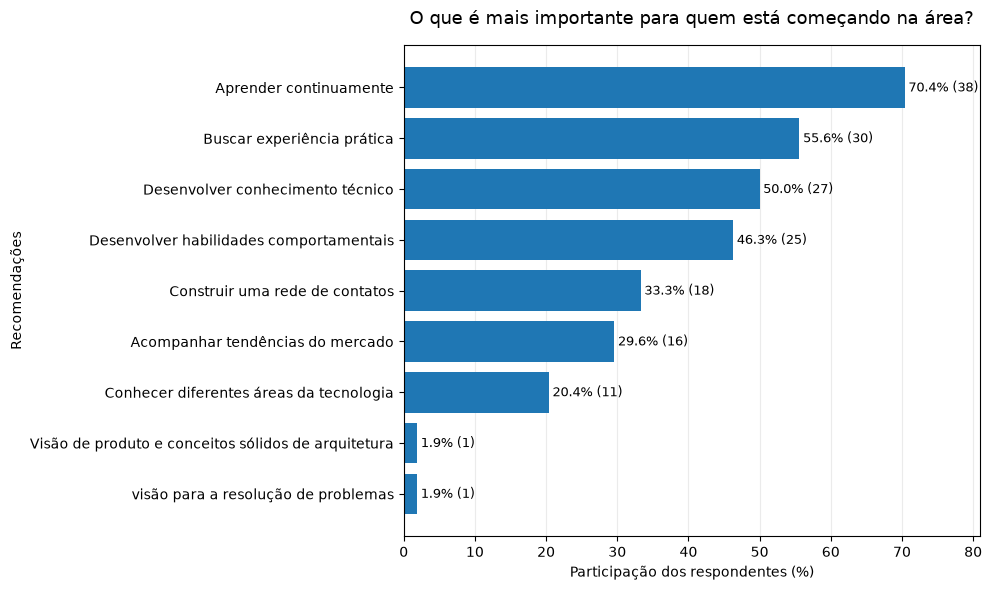

In [28]:
# Visualização — Recomendações para quem está começando

fig, ax = plt.subplots(figsize=(10, 6))

dados = tabela_recomendacoes.sort_values("Percentual (%)", ascending=True)

barras = ax.barh(dados.index, dados["Percentual (%)"])

ax.set_title(
    "O que é mais importante para quem está começando na área?", fontsize=13, pad=15
)

ax.set_xlabel("Participação dos respondentes (%)")
ax.set_ylabel("Recomendações")

ax.set_xlim(0, dados["Percentual (%)"].max() * 1.15)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for barra, percentual, participantes in zip(
    barras, dados["Percentual (%)"], dados["Participantes"]
):
    ax.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.1f}% ({participantes})",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

### Leitura analítica

As respostas apontam para uma valorização expressiva do aprendizado contínuo (70,4%), seguido pela busca de experiência prática (55,6%) e pelo desenvolvimento de conhecimento técnico (50%). Esses três aspectos aparecem como as recomendações mais recorrentes entre os participantes.

O desenvolvimento de habilidades comportamentais também ocupa posição relevante, com 46,3% das marcações, indicando que a preparação profissional é percebida para além do domínio técnico.

Outros aspectos, como construir uma rede de contatos (33,3%) e acompanhar tendências do mercado (29,6%), também aparecem entre as recomendações, embora com menor frequência.

Os resultados sugerem que, na percepção dos participantes, a entrada na área de tecnologia exige uma combinação de iniciativa para aprender, oportunidade de aplicar conhecimentos na prática e desenvolvimento de competências técnicas e comportamentais.

A predominância do aprendizado contínuo merece destaque: mais de dois terços dos participantes o assinalaram, reforçando a importância atribuída à atualização constante em um campo profissional marcado por mudanças.

### 04.2 — Combinações das recomendações

Esta etapa investiga como as recomendações selecionadas pelos participantes aparecem combinadas em suas respostas.

A análise identifica as combinações mais recorrentes e sua distribuição entre os participantes, permitindo observar quais orientações tendem a ser associadas umas às outras.

In [29]:
# 04.2 — Combinações das recomendações

# 1. Organização das respostas
combinacoes_recomendacoes = (
    df_realidade[coluna_recomendacoes]
    .dropna()
    .apply(
        lambda resposta: tuple(
            sorted(item.strip() for item in resposta.split(",") if item.strip())
        )
    )
)

# 2. Contagem das combinações
frequencia_combinacoes_recomendacoes = (
    combinacoes_recomendacoes.value_counts()
    .rename_axis("Combinação")
    .reset_index(name="Participantes")
)

# 3. Cálculo dos percentuais
total_respostas_validas = len(combinacoes_recomendacoes)

frequencia_combinacoes_recomendacoes["Percentual (%)"] = (
    frequencia_combinacoes_recomendacoes["Participantes"]
    / total_respostas_validas
    * 100
).round(1)

# 4. Exibição dos resultados
print("COMBINAÇÕES DAS RECOMENDAÇÕES")
print(f"Total de participantes: {total_respostas_validas}")
print("Combinações distintas identificadas:", len(frequencia_combinacoes_recomendacoes))

display(frequencia_combinacoes_recomendacoes)

COMBINAÇÕES DAS RECOMENDAÇÕES
Total de participantes: 54
Combinações distintas identificadas: 35


,Combinação,Participantes,Percentual (%)
0,"(Aprender continuamente, Buscar experiência pr...",5,9.3
1,"(Aprender continuamente, Desenvolver conhecime...",4,7.4
2,"(Acompanhar tendências do mercado, Aprender co...",3,5.6
3,"(Aprender continuamente, Buscar experiência pr...",3,5.6
4,"(Acompanhar tendências do mercado, Aprender co...",3,5.6
5,"(Aprender continuamente, Construir uma rede de...",3,5.6
6,"(Buscar experiência prática, Desenvolver conhe...",3,5.6
7,"(Acompanhar tendências do mercado, Buscar expe...",2,3.7
8,"(Aprender continuamente, Construir uma rede de...",2,3.7
9,"(Aprender continuamente, visão para a resoluçã...",1,1.9


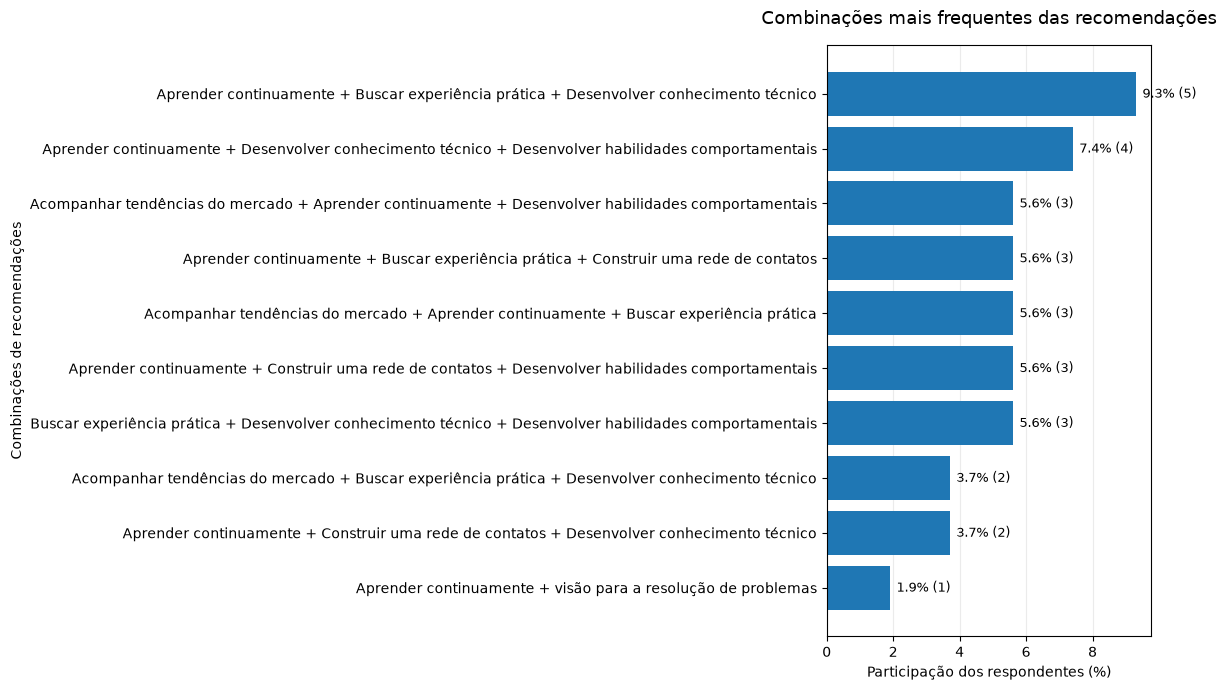

In [30]:
# Visualização das combinações mais frequentes

import matplotlib.pyplot as plt

top_combinacoes = (
    frequencia_combinacoes_recomendacoes.sort_values(
        by="Participantes", ascending=False
    )
    .head(10)
    .copy()
)

rotulos = [" + ".join(combinacao) for combinacao in top_combinacoes["Combinação"]]

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(rotulos[::-1], top_combinacoes["Percentual (%)"].values[::-1])

ax.set_title("Combinações mais frequentes das recomendações", fontsize=13, pad=15)

ax.set_xlabel("Participação dos respondentes (%)")
ax.set_ylabel("Combinações de recomendações")

for barra, percentual, quantidade in zip(
    barras,
    top_combinacoes["Percentual (%)"].values[::-1],
    top_combinacoes["Participantes"].values[::-1],
):
    ax.text(
        barra.get_width() + 0.2,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.1f}% ({quantidade})",
        va="center",
        fontsize=9,
    )

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

As combinações identificadas revelam diversidade nas recomendações consideradas importantes para quem está começando na área de tecnologia. Entre os 54 participantes, foram encontradas 35 combinações distintas, indicando que as orientações não se concentram em um único conjunto de recomendações.

A combinação mais frequente reúne **aprendizado contínuo, busca por experiência prática e desenvolvimento de conhecimento técnico**, assinalada por 5 participantes (9,3%). Em seguida, aparece a associação entre aprendizado contínuo, conhecimento técnico e desenvolvimento de habilidades comportamentais, com 4 participantes (7,4%).

Outras combinações recorrentes também articulam aprendizado contínuo, experiência prática, conhecimento técnico e habilidades comportamentais, embora com frequências menores. Esses elementos aparecem em diferentes associações, sugerindo que os participantes reconhecem múltiplas dimensões na preparação de quem ingressa no setor.

A diversidade das respostas é um achado relevante: nenhuma combinação concentra uma parcela expressiva da amostra. Portanto, os resultados não apontam para um roteiro único de entrada na tecnologia, mas para diferentes maneiras de combinar conhecimentos, experiências e atitudes.

**Implicação analítica:** as recomendações valorizam uma preparação que vai além da formação técnica isolada. Aprender continuamente, desenvolver conhecimentos, buscar experiências práticas e fortalecer habilidades comportamentais aparecem como componentes que podem se complementar, ainda que não exista uma combinação predominante.

## 05 — Cruzamentos exploratórios

Esta etapa investiga como as recomendações consideradas importantes para quem está começando na área de tecnologia se distribuem entre diferentes grupos de participantes.

A análise contempla dois cruzamentos:

1. **Recomendações × Faixa etária:** observa possíveis diferenças nas orientações selecionadas por participantes de diferentes faixas etárias.
2. **Recomendações × Tempo de atuação:** identifica como as recomendações se distribuem entre profissionais com diferentes tempos de experiência na área.

Os percentuais representam a proporção de participantes de cada grupo que selecionou determinada recomendação. Como os grupos possuem tamanhos diferentes e a questão permite múltiplas escolhas, os resultados devem ser interpretados considerando essas características e os limites da amostra investigada.

O plano de análise também previa outros cruzamentos exploratórios envolvendo cotidiano profissional, área de atuação e correspondência entre realidade e expectativa. Essas possibilidades não foram incorporadas à execução final. Assim, a análise foi delimitada aos dois cruzamentos apresentados, sem pretensão de esgotar todas as relações possíveis entre as variáveis investigadas.

In [31]:
# 05.1 — Distribuição dos grupos para os cruzamentos

# 1. Identificação das colunas na base original
colunas_disponiveis = {coluna.strip(): coluna for coluna in df_original.columns}

coluna_idade = colunas_disponiveis["Faixa Etária"]
coluna_tempo = colunas_disponiveis["Tempo de atuação na Área"]
coluna_area = colunas_disponiveis["Área de Atuação"]

# 2. Distribuição por faixa etária
print("DISTRIBUIÇÃO POR FAIXA ETÁRIA")

display(df_original[coluna_idade].value_counts().to_frame("Participantes"))

# 3. Distribuição por tempo de atuação
print("\nDISTRIBUIÇÃO POR TEMPO DE ATUAÇÃO")

display(df_original[coluna_tempo].value_counts().to_frame("Participantes"))

# 4. Distribuição por área de atuação
print("\nDISTRIBUIÇÃO POR ÁREA DE ATUAÇÃO")

areas_participantes = (
    df_original[coluna_area].dropna().str.split(",").explode().str.strip()
)

display(areas_participantes.value_counts().to_frame("Participações"))

print("\nDISTRIBUIÇÕES CONFERIDAS.")

DISTRIBUIÇÃO POR FAIXA ETÁRIA


,Participantes
Faixa Etária,
45–54,14
35–44,14
Até 24,9
25–34,9
55 ou mais,7
Prefiro não informar,1



DISTRIBUIÇÃO POR TEMPO DE ATUAÇÃO


,Participantes
Tempo de atuação na Área,
1–3 anos,15
4–7 anos,11
Mais de 15 anos,11
8–15 anos,9
Menos de 1 ano,8



DISTRIBUIÇÃO POR ÁREA DE ATUAÇÃO


,Participações
Área de Atuação,
Desenvolvimento de Software,27
Analise de Dados/ Analytics,15
Inteligência Artificial/ Machine Learning,14
Gestão de Projetos em Tecnologia,11
Arquitetura de Soluções,6
UX/ UI/ Design de Produto,6
Produto/ Produto Management,5
Business Intelligence (BI),5
Cibersegurança,4



DISTRIBUIÇÕES CONFERIDAS.


In [32]:
# 05.2 — Recomendações × tempo de atuação

import pandas as pd
import re
import unicodedata

# 1. Identificação das colunas
colunas_disponiveis = {
    coluna.strip().casefold(): coluna for coluna in df_original.columns
}

coluna_tempo = colunas_disponiveis["tempo de atuação na área"]

coluna_recomendacoes = colunas_disponiveis[
    "o que você considera mais importante para quem está começando na sua área?"
]

# 2. Construção da base de trabalho
df_tempo_recomendacoes = df_original[[coluna_tempo, coluna_recomendacoes]].copy()

df_tempo_recomendacoes.columns = ["Tempo de atuação", "Recomendações"]


# 3. Padronização das categorias de experiência
def normalizar_tempo(valor):

    texto = str(valor).strip().casefold()

    texto = texto.replace("–", "-").replace("—", "-")

    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        caractere for caractere in texto if not unicodedata.combining(caractere)
    )

    texto = re.sub(r"\s+", " ", texto)

    mapa_tempo = {
        "menos de 1 ano": "Menos de 1 ano",
        "1-3 anos": "1-3 anos",
        "4-7 anos": "4-7 anos",
        "8-15 anos": "8-15 anos",
        "mais de 15 anos": "Mais de 15 anos",
    }

    return mapa_tempo.get(texto)


df_tempo_recomendacoes["Tempo de atuação"] = df_tempo_recomendacoes[
    "Tempo de atuação"
].apply(normalizar_tempo)

# 4. Conferência das categorias reconhecidas
ordem_tempo = ["Menos de 1 ano", "1-3 anos", "4-7 anos", "8-15 anos", "Mais de 15 anos"]

if df_tempo_recomendacoes["Tempo de atuação"].isna().any():
    valores_nao_reconhecidos = (
        df_original.loc[df_tempo_recomendacoes["Tempo de atuação"].isna(), coluna_tempo]
        .unique()
        .tolist()
    )

    raise ValueError(
        f"Categorias de tempo não reconhecidas: {valores_nao_reconhecidos}"
    )

# 5. Distribuição dos participantes por experiência
contagem_tempo = (
    df_tempo_recomendacoes["Tempo de atuação"]
    .value_counts()
    .reindex(ordem_tempo, fill_value=0)
)

print("DISTRIBUIÇÃO DOS PARTICIPANTES POR TEMPO DE ATUAÇÃO")

display(contagem_tempo.to_frame("Participantes"))

# 6. Separação das múltiplas recomendações
df_tempo_explodido = df_tempo_recomendacoes.copy()

df_tempo_explodido["Recomendações"] = (
    df_tempo_explodido["Recomendações"].fillna("").str.split(",")
)

df_tempo_explodido = df_tempo_explodido.explode("Recomendações")

df_tempo_explodido["Recomendações"] = df_tempo_explodido["Recomendações"].str.strip()

df_tempo_explodido = df_tempo_explodido[
    df_tempo_explodido["Recomendações"] != ""
].copy()

# 7. Frequência absoluta por recomendação e tempo de atuação
tabela_tempo_recomendacoes = pd.crosstab(
    df_tempo_explodido["Recomendações"], df_tempo_explodido["Tempo de atuação"]
)

tabela_tempo_recomendacoes = tabela_tempo_recomendacoes.reindex(
    columns=ordem_tempo, fill_value=0
)

print("\nFREQUÊNCIA DE RECOMENDAÇÕES POR TEMPO DE ATUAÇÃO")

display(tabela_tempo_recomendacoes)

# 8. Seleção dos grupos para comparação percentual
# Todos os grupos possuem mais de um participante.

grupos_comparaveis_tempo = [grupo for grupo in ordem_tempo if contagem_tempo[grupo] > 1]

frequencias_tempo_comparaveis = tabela_tempo_recomendacoes[grupos_comparaveis_tempo]

denominadores_tempo = contagem_tempo[grupos_comparaveis_tempo]

# 9. Cálculo dos percentuais dentro de cada grupo
percentual_cruzamento_tempo = frequencias_tempo_comparaveis.div(
    denominadores_tempo, axis=1
).mul(100)

print("\nPERCENTUAL DE PARTICIPANTES EM CADA GRUPO")

display(percentual_cruzamento_tempo.round(1))

print("\nCRUZAMENTO CONCLUÍDO.")

DISTRIBUIÇÃO DOS PARTICIPANTES POR TEMPO DE ATUAÇÃO


,Participantes
Tempo de atuação,
Menos de 1 ano,8
1-3 anos,15
4-7 anos,11
8-15 anos,9
Mais de 15 anos,11



FREQUÊNCIA DE RECOMENDAÇÕES POR TEMPO DE ATUAÇÃO


Tempo de atuação,Menos de 1 ano,1-3 anos,4-7 anos,8-15 anos,Mais de 15 anos
Recomendações,,,,,
Acompanhar tendências do mercado,4,3,5,3,1
Aprender continuamente,7,10,7,6,8
Buscar experiência prática,8,9,7,3,3
Conhecer diferentes áreas da tecnologia,3,2,2,2,2
Construir uma rede de contatos,1,6,3,2,6
Desenvolver conhecimento técnico,3,9,5,4,6
Desenvolver habilidades comportamentais,0,10,3,4,8
Visão de produto e conceitos sólidos de arquitetura,0,0,0,0,1
visão para a resolução de problemas,0,1,0,0,0



PERCENTUAL DE PARTICIPANTES EM CADA GRUPO


Tempo de atuação,Menos de 1 ano,1-3 anos,4-7 anos,8-15 anos,Mais de 15 anos
Recomendações,,,,,
Acompanhar tendências do mercado,50.0,20.0,45.5,33.3,9.1
Aprender continuamente,87.5,66.7,63.6,66.7,72.7
Buscar experiência prática,100.0,60.0,63.6,33.3,27.3
Conhecer diferentes áreas da tecnologia,37.5,13.3,18.2,22.2,18.2
Construir uma rede de contatos,12.5,40.0,27.3,22.2,54.5
Desenvolver conhecimento técnico,37.5,60.0,45.5,44.4,54.5
Desenvolver habilidades comportamentais,0.0,66.7,27.3,44.4,72.7
Visão de produto e conceitos sólidos de arquitetura,0.0,0.0,0.0,0.0,9.1
visão para a resolução de problemas,0.0,6.7,0.0,0.0,0.0



CRUZAMENTO CONCLUÍDO.


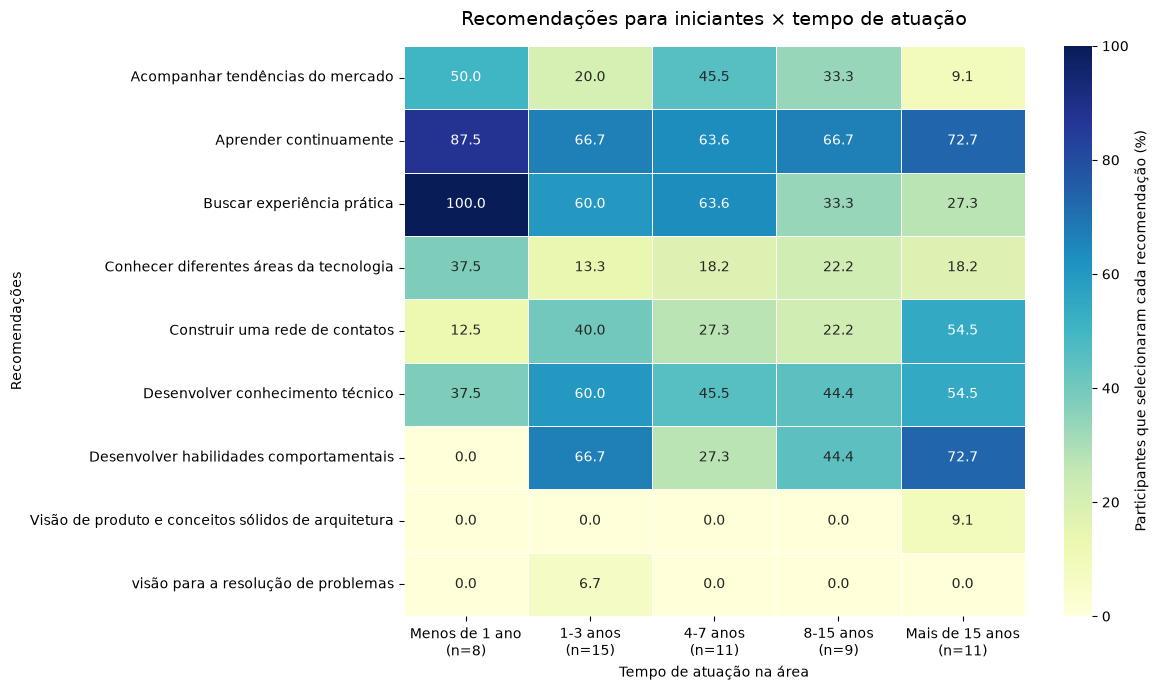


HEATMAP GERADO COM SUCESSO.


In [33]:
# 05.2.1 — Heatmap: Recomendações × tempo de atuação

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação da matriz percentual
dados_heatmap_tempo = percentual_cruzamento_tempo.copy()

# 2. Inclusão do tamanho de cada grupo nos rótulos
dados_heatmap_tempo.columns = [
    f"{grupo}\n(n={contagem_tempo[grupo]})" for grupo in dados_heatmap_tempo.columns
]

# 3. Construção do heatmap
fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    dados_heatmap_tempo,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Participantes que selecionaram cada recomendação (%)"},
    ax=ax,
)

# 4. Título e identificação dos eixos
ax.set_title("Recomendações para iniciantes × tempo de atuação", fontsize=14, pad=15)

ax.set_xlabel("Tempo de atuação na área")
ax.set_ylabel("Recomendações")

# 5. Ajustes de leitura
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nHEATMAP GERADO COM SUCESSO.")

### Leitura analítica

A recomendação de **aprender continuamente** apresenta percentuais elevados em todos os grupos de experiência, variando de 63,6% a 87,5%. O resultado indica que a atualização constante é valorizada tanto por profissionais em início de carreira quanto por aqueles com maior tempo de atuação.

A **busca por experiência prática** apresenta maior frequência entre os participantes com menos de um ano de atuação (100%). Também aparece com destaque nos grupos de 1 a 3 anos (60%) e de 4 a 7 anos (63,6%). Entre os participantes com mais de 7 anos de experiência, os percentuais são menores, chegando a 27,3% no grupo com mais de 15 anos.

O **desenvolvimento de habilidades comportamentais** apresenta diferenças entre os grupos. A recomendação foi assinalada por 66,7% dos participantes com 1 a 3 anos e por 72,7% daqueles com mais de 15 anos. Nos grupos intermediários, os percentuais foram de 27,3% entre 4 e 7 anos e 44,4% entre 8 e 15 anos. Não houve registros entre os participantes com menos de um ano de atuação.

A **construção de uma rede de contatos** ganha destaque entre os profissionais mais experientes: 54,5% daqueles com mais de 15 anos assinalaram essa recomendação. Entre os participantes com 1 a 3 anos, o percentual foi de 40%. Nos demais grupos, variou entre 12,5% e 27,3%.

O **desenvolvimento do conhecimento técnico** aparece em todos os grupos, com percentuais entre 37,5% e 60%. Já o acompanhamento das tendências do mercado apresenta maior frequência entre participantes com menos de um ano de atuação (50%) e entre aqueles com 4 a 7 anos (45,5%).

As recomendações relacionadas à visão de produto, arquitetura e resolução de problemas tiveram baixa frequência. A visão de produto e os conceitos de arquitetura foram assinalados apenas por um participante do grupo com mais de 15 anos (9,1%), enquanto a visão para resolução de problemas apareceu em um participante do grupo de 1 a 3 anos (6,7%).

Em conjunto, os resultados indicam diferentes ênfases nas recomendações conforme o tempo de atuação. A aprendizagem contínua atravessa todos os grupos; a experiência prática ganha destaque principalmente entre os profissionais em início de carreira; e o networking e as habilidades comportamentais aparecem com maior frequência em determinados grupos de experiência. Essas diferenças representam tendências observadas na amostra, não uma sequência obrigatória de necessidades ao longo da carreira.

**Nota metodológica:** os percentuais representam a proporção de participantes de cada grupo de experiência que selecionou determinada recomendação. Os grupos possuem tamanhos distintos, variando de 8 a 15 participantes. As diferenças devem ser interpretadas considerando também os números absolutos e os limites da amostra investigada.

DISTRIBUIÇÃO DAS FAIXAS ETÁRIAS


,Participantes
Faixa etária,
Até 24,9
25-34,9
35-44,14
45-54,14
55 ou mais,7
Prefiro não informar,1



FREQUÊNCIA DE RECOMENDAÇÕES POR FAIXA ETÁRIA


Faixa etária,Até 24,25-34,35-44,45-54,55 ou mais,Prefiro não informar
Recomendações,,,,,,
Acompanhar tendências do mercado,1,5,3,3,3,1
Aprender continuamente,5,7,10,9,6,1
Buscar experiência prática,7,5,7,5,5,1
Conhecer diferentes áreas da tecnologia,2,1,2,5,0,1
Construir uma rede de contatos,2,2,5,5,3,1
Desenvolver conhecimento técnico,7,5,5,6,3,1
Desenvolver habilidades comportamentais,5,3,8,7,2,0
Visão de produto e conceitos sólidos de arquitetura,0,0,0,1,0,0
visão para a resolução de problemas,0,0,0,1,0,0



PERCENTUAL DE PARTICIPANTES EM CADA GRUPO


,Até 24\n(n=9),25-34\n(n=9),35-44\n(n=14),45-54\n(n=14),55 ou mais\n(n=7)
Recomendações,,,,,
Acompanhar tendências do mercado,11.1,55.6,21.4,21.4,42.9
Aprender continuamente,55.6,77.8,71.4,64.3,85.7
Buscar experiência prática,77.8,55.6,50.0,35.7,71.4
Conhecer diferentes áreas da tecnologia,22.2,11.1,14.3,35.7,0.0
Construir uma rede de contatos,22.2,22.2,35.7,35.7,42.9
Desenvolver conhecimento técnico,77.8,55.6,35.7,42.9,42.9
Desenvolver habilidades comportamentais,55.6,33.3,57.1,50.0,28.6
Visão de produto e conceitos sólidos de arquitetura,0.0,0.0,0.0,7.1,0.0
visão para a resolução de problemas,0.0,0.0,0.0,7.1,0.0


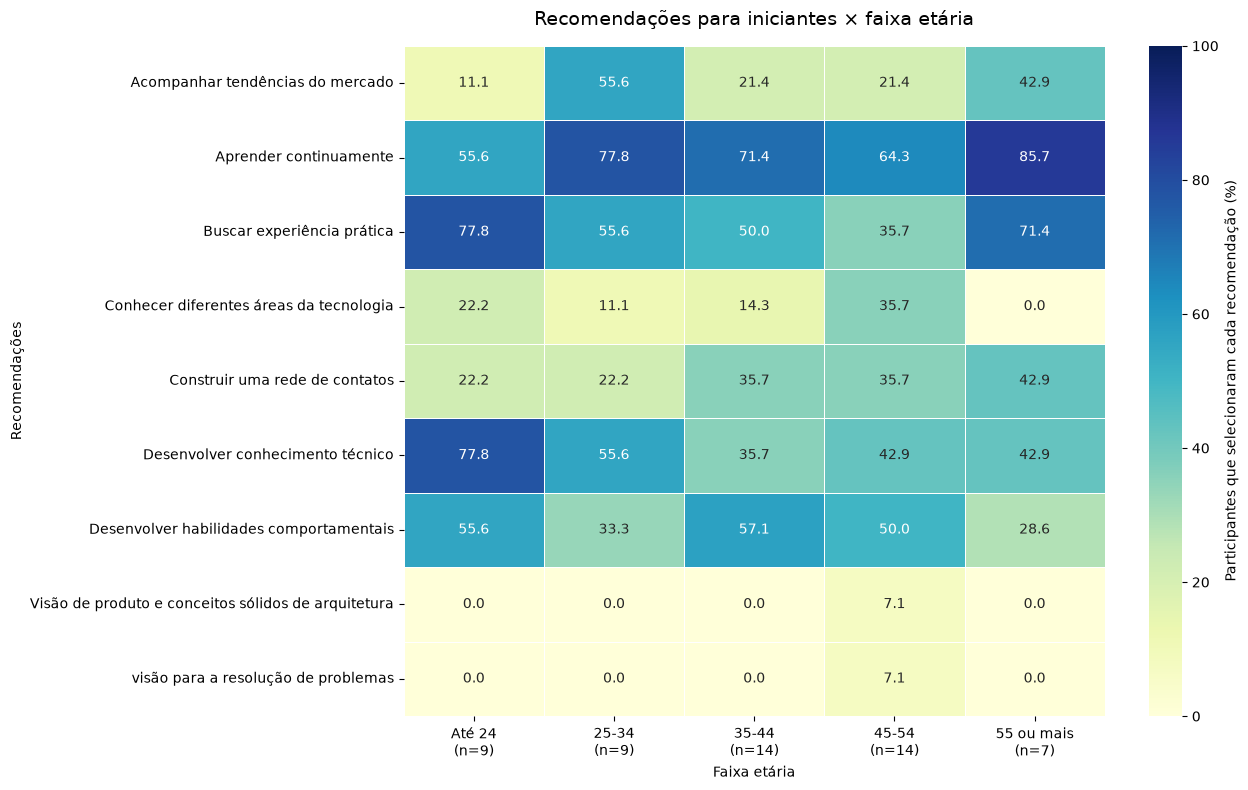


HEATMAP GERADO COM SUCESSO.


In [34]:
# CRUZAMENTO — RECOMENDAÇÕES × FAIXA ETÁRIA

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

# 1. Identificação das colunas originais
colunas = {coluna.strip().casefold(): coluna for coluna in df_original.columns}

coluna_idade = colunas["faixa etária"]

coluna_recomendacoes = colunas[
    "o que você considera mais importante para quem está começando na sua área?"
]

# 2. Construção da base de trabalho
df_cruzamento = df_original[[coluna_idade, coluna_recomendacoes]].copy()

df_cruzamento.columns = ["Faixa etária", "Recomendações"]


# 3. Padronização das faixas etárias
def normalizar_texto(valor):
    valor = str(valor).strip().casefold()
    valor = unicodedata.normalize("NFKD", valor)

    valor = "".join(
        caractere for caractere in valor if not unicodedata.combining(caractere)
    )

    return valor


def normalizar_faixa(valor):
    texto = normalizar_texto(valor)
    texto = texto.replace("–", "-").replace("—", "-")

    if "ate" in texto and "24" in texto:
        return "Até 24"

    numeros = re.findall(r"\d+", texto)

    if len(numeros) >= 2:
        intervalo = (numeros[0], numeros[1])

        mapa_intervalos = {
            ("25", "34"): "25-34",
            ("35", "44"): "35-44",
            ("45", "54"): "45-54",
        }

        if intervalo in mapa_intervalos:
            return mapa_intervalos[intervalo]

    if "55" in texto and "mais" in texto:
        return "55 ou mais"

    if "prefiro" in texto and "informar" in texto:
        return "Prefiro não informar"

    return None


df_cruzamento["Faixa etária"] = df_cruzamento["Faixa etária"].apply(normalizar_faixa)


# 4. Conferência das categorias reconhecidas
ordem_idade = [
    "Até 24",
    "25-34",
    "35-44",
    "45-54",
    "55 ou mais",
    "Prefiro não informar",
]

if df_cruzamento["Faixa etária"].isna().any():
    raise ValueError(
        "Existem faixas etárias não reconhecidas. "
        "Confira os valores originais da coluna."
    )


# 5. Contagem de participantes por faixa etária
contagem_grupos = (
    df_cruzamento["Faixa etária"].value_counts().reindex(ordem_idade, fill_value=0)
)

print("DISTRIBUIÇÃO DAS FAIXAS ETÁRIAS")

display(contagem_grupos.to_frame("Participantes"))


# 6. Separação das recomendações selecionadas
df_explodido = df_cruzamento.copy()

df_explodido["Recomendações"] = df_explodido["Recomendações"].fillna("").str.split(",")

df_explodido = df_explodido.explode("Recomendações")

df_explodido["Recomendações"] = df_explodido["Recomendações"].str.strip()

df_explodido = df_explodido[df_explodido["Recomendações"] != ""].copy()


# 7. Frequência absoluta de recomendações por faixa etária
tabela_frequencias = pd.crosstab(
    df_explodido["Recomendações"], df_explodido["Faixa etária"]
)

tabela_frequencias = tabela_frequencias.reindex(columns=ordem_idade, fill_value=0)

print("\nFREQUÊNCIA DE RECOMENDAÇÕES POR FAIXA ETÁRIA")

display(tabela_frequencias)


# 8. Seleção dos grupos adequados para comparação percentual
# Grupos com apenas um participante não entram na comparação.

grupos_comparaveis = contagem_grupos[contagem_grupos > 1].index.tolist()

contagem_comparavel = contagem_grupos[grupos_comparaveis]

frequencias_comparaveis = tabela_frequencias[grupos_comparaveis]


# 9. Cálculo do percentual dentro de cada grupo
percentual_heatmap = frequencias_comparaveis.div(contagem_comparavel, axis=1).mul(100)

rotulos_colunas = [
    f"{faixa}\n(n={contagem_comparavel[faixa]})" for faixa in grupos_comparaveis
]

percentual_heatmap.columns = rotulos_colunas

print("\nPERCENTUAL DE PARTICIPANTES EM CADA GRUPO")

display(percentual_heatmap.round(1))


# 10. Construção do heatmap
plt.figure(figsize=(13, 8))

sns.heatmap(
    percentual_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Participantes que selecionaram cada recomendação (%)"},
)

# 11. Títulos e identificação dos eixos
plt.title("Recomendações para iniciantes × faixa etária", fontsize=14, pad=15)

plt.xlabel("Faixa etária")
plt.ylabel("Recomendações")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nHEATMAP GERADO COM SUCESSO.")

### Leitura analítica

A recomendação de **aprender continuamente** apresenta percentuais elevados em todas as faixas etárias, variando de 55,6% a 85,7%. O resultado indica que a atualização constante é valorizada pelos participantes, independentemente da idade.

A **busca por experiência prática** apresenta maior percentual entre os participantes de até 24 anos (77,8%) e entre aqueles com 55 anos ou mais (71,4%). Nas faixas intermediárias, os percentuais são menores, chegando a 35,7% entre 45 e 54 anos.

O **desenvolvimento de conhecimento técnico** também aparece com destaque entre os participantes de até 24 anos (77,8%). Nas demais faixas, os percentuais variam de 35,7% a 55,6%, indicando que essa recomendação está presente em diferentes momentos da trajetória profissional.

O **desenvolvimento de habilidades comportamentais** apresenta maior percentual entre participantes de 35 a 44 anos (57,1%), seguido pela faixa de 45 a 54 anos (50%). Entre os participantes com 55 anos ou mais, o percentual é de 28,6%.

A **construção de uma rede de contatos** apresenta percentuais mais elevados nas faixas a partir dos 35 anos: 35,7% entre 35 e 44 anos, 35,7% entre 45 e 54 anos e 42,9% entre aqueles com 55 anos ou mais. Já o acompanhamento das tendências do mercado se destaca entre participantes de 25 a 34 anos (55,6%).

As recomendações relacionadas a **conhecer diferentes áreas da tecnologia** aparecem com maior percentual entre participantes de 45 a 54 anos (35,7%). Já visão de produto, conceitos de arquitetura e visão para resolução de problemas apresentam baixa incidência, com registros apenas pontuais na faixa de 45 a 54 anos.

Em conjunto, os resultados mostram que algumas recomendações atravessam diferentes faixas etárias, especialmente a aprendizagem contínua. Outras apresentam variações entre os grupos, como experiência prática, conhecimento técnico, desenvolvimento comportamental e networking. Essas diferenças indicam distintas ênfases observadas na amostra, sem estabelecer relações causais entre idade e recomendações profissionais.

**Nota metodológica:** os percentuais representam a proporção de participantes de cada faixa etária que selecionou determinada recomendação. Os grupos possuem tamanhos diferentes, variando de 7 a 14 participantes. Por isso, as diferenças devem ser interpretadas considerando também os números absolutos e os limites da amostra investigada.

# 06 — Síntese analítica — Eixo 3: Realidade

*Articulação dos resultados sobre o cotidiano profissional, a percepção da realidade em relação às expectativas iniciais e as recomendações para quem está ingressando na área de tecnologia, considerando as combinações de respostas e os cruzamentos exploratórios.*

A análise evidencia um cotidiano profissional marcado principalmente pela capacidade de resolução de problemas e pela aprendizagem contínua. Essas características foram as mais assinaladas pelos participantes, indicando a relevância atribuída tanto à aplicação de conhecimentos na prática quanto à atualização constante em um campo profissional em transformação.

A diversidade de combinações identificadas entre as características do cotidiano reforça que a experiência profissional não se organiza em um conjunto único de competências. Embora resolução de problemas, aprendizagem contínua e conhecimento técnico apareçam com frequência, as respostas demonstram diferentes formas de articulação entre aspectos técnicos, comportamentais e relacionais na descrição do cotidiano de trabalho.

Em relação à correspondência entre a realidade profissional e as expectativas iniciais, as respostas se concentram entre o ponto intermediário e a parte superior da escala de 1 a 5. A nota 3 foi a mais frequente (40,7%), 51,9% dos participantes atribuíram as notas 4 ou 5 e 7,4% atribuíram as notas 1 ou 2. A distribuição mostra que as percepções não se concentram em um único valor. O significado de cada valor deve ser lido conforme os rótulos originais da escala no formulário.

As recomendações destinadas a quem está ingressando na tecnologia retomam temas presentes na caracterização do cotidiano. Aprendizagem contínua, experiência prática e desenvolvimento de conhecimento técnico aparecem entre as orientações mais selecionadas. Também se destacam as habilidades comportamentais e a construção de redes de contato, indicando que a preparação para atuar no setor é percebida como algo que ultrapassa o domínio técnico.

As combinações de recomendações apresentam novamente uma distribuição diversificada, sem concentração expressiva em um único conjunto de orientações. Esse resultado sugere que os participantes reconhecem diferentes caminhos de preparação, articulando conhecimentos, experiências e atitudes conforme suas percepções sobre as exigências da área.

Os cruzamentos exploratórios acrescentam diferenças de ênfase entre os grupos. A aprendizagem contínua mantém percentuais elevados nas diferentes faixas etárias e tempos de atuação. A experiência prática ganha destaque entre os participantes mais jovens e aqueles com menos tempo de carreira, enquanto a construção de redes de contato aparece com maior frequência entre os grupos de maior idade e experiência. O desenvolvimento de habilidades comportamentais também apresenta variações entre os grupos, sem estabelecer uma progressão uniforme ao longo da trajetória profissional.

Em conjunto, os resultados revelam convergências temáticas entre as características identificadas no cotidiano profissional e as recomendações destinadas a quem está começando. A aprendizagem contínua e o conhecimento técnico aparecem nas duas dimensões, enquanto as recomendações também incorporam experiência prática, habilidades comportamentais e construção de redes de contato. Essa aproximação é descritiva: não foi realizado um cruzamento direto entre essas variáveis.

**Implicação analítica:** a realidade profissional descrita pelos participantes aponta para uma experiência que combina atualização permanente, aplicação prática do conhecimento e competências de interação e adaptação. As recomendações para iniciantes retomam esses temas e ampliam a perspectiva ao incorporar diferentes dimensões da preparação profissional, sem indicar uma única trajetória ou combinação considerada suficiente para ingressar e permanecer na área.

**Nota metodológica:** os resultados representam as percepções dos 54 participantes da amostra investigada. As questões de múltipla escolha permitem que um mesmo participante assinale diferentes características e recomendações, e a questão de recomendações permitia até três seleções por participante. Nos cruzamentos, os percentuais representam a proporção de participantes de cada grupo que selecionou determinada opção. Como os grupos possuem tamanhos distintos e reduzidos, as diferenças observadas devem ser interpretadas como tendências da amostra, sem estabelecer relações causais ou generalizações para o conjunto dos profissionais de tecnologia.

# 07 — Encerramento do Eixo 3 — Realidade

### Delimitação do eixo

A análise deste eixo esteve concentrada nas percepções dos 54 participantes sobre o cotidiano profissional, na correspondência entre a realidade vivenciada e as expectativas iniciais e nas recomendações que consideram importantes para quem está começando na área de tecnologia.

Os resultados expressam as experiências e avaliações declaradas pelos participantes da amostra investigada. Os cruzamentos exploratórios permitem observar diferenças entre grupos, mas não estabelecem relações causais, trajetórias obrigatórias ou generalizações para o conjunto dos profissionais de tecnologia.

### Continuidade da investigação

A pesquisa avança da compreensão da realidade profissional vivenciada pelos participantes para as orientações e perspectivas que eles desejam compartilhar com quem está começando na área:

- **Eixo 4 — Olhando para frente:** retoma a pergunta sobre o que é importante para quem está começando, agora articulada às respostas abertas, com alertas, tendências e recomendações compartilhados pelos participantes.